<a href="https://colab.research.google.com/github/RoqaiaWagih/DIP-Image-Compression-Benchmark/blob/main/notebooks/Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy pillow matplotlib scikit-image pytorch-msssim

Image dimensions: (768, 512)


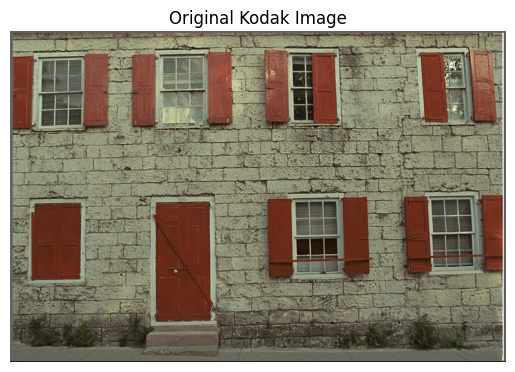

In [2]:

from pathlib import Path
from PIL import Image
import requests
import matplotlib.pyplot as plt

ROOT = Path("/content/DIP_Project")
original_folder = ROOT / "datasets/kodak"
original_folder.mkdir(parents=True, exist_ok=True)

image_path = original_folder / "kodim01.png"

if not image_path.exists():
    url = "https://r0k.us/graphics/kodak/kodak/kodim01.png"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    image_path.write_bytes(response.content)

original = Image.open(image_path).convert("RGB")

print("Image dimensions:", original.size)

plt.imshow(original)
plt.title("Original Kodak Image")
plt.axis("off")
plt.show()


**Calculate PSNR, SSIM, and MS-SSIM**

In [3]:

import numpy as np
import torch

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
from pytorch_msssim import ms_ssim

def evaluate_images(original, reconstructed):

    # Both images must have identical dimensions
    if original.size != reconstructed.size:
        raise ValueError("Image dimensions do not match")

    original_array = np.array(original.convert("RGB"))
    reconstructed_array = np.array(
        reconstructed.convert("RGB")
    )

    # PSNR
    psnr = peak_signal_noise_ratio(
        original_array,
        reconstructed_array,
        data_range=255
    )

    # SSIM
    ssim_value = structural_similarity(
        original_array,
        reconstructed_array,
        channel_axis=-1,
        data_range=255
    )

    # Convert HWC -> NCHW tensors, pixel range [0,1]
    x = torch.from_numpy(
        original_array.copy()
    ).permute(2, 0, 1).unsqueeze(0).float() / 255.0

    y = torch.from_numpy(
        reconstructed_array.copy()
    ).permute(2, 0, 1).unsqueeze(0).float() / 255.0

    # MS-SSIM, requires sufficiently large images
    ms_ssim_value = ms_ssim(
        x, y,
        data_range=1.0,
        size_average=True
    ).item()

    return {
        "PSNR (dB)": float(psnr),
        "SSIM": float(ssim_value),
        "MS-SSIM": float(ms_ssim_value)
    }


In [4]:

from io import BytesIO

buffer = BytesIO()

original.save(
    buffer,
    format="JPEG",
    quality=50
)

compressed_bytes = len(buffer.getvalue())
buffer.seek(0)

reconstructed = Image.open(buffer).convert("RGB")

metrics = evaluate_images(original, reconstructed)

width, height = original.size
bpp = 8 * compressed_bytes / (width * height)

print("JPEG Quality: 50")
print("Compressed size:", compressed_bytes, "bytes")
print("bpp:", round(bpp, 4))

for key, value in metrics.items():
    print(f"{key}: {value:.4f}")


JPEG Quality: 50
Compressed size: 61794 bytes
bpp: 1.2572
PSNR (dB): 29.8679
SSIM: 0.8918
MS-SSIM: 0.9823


**Generate distortion graph**

,Codec,Quality,bpp,PSNR,SSIM,MS-SSIM
0,JPEG,10,0.439840,24.774125,0.706633,0.917762
1,JPEG,30,0.922323,28.211136,0.848398,0.970903
2,JPEG,50,1.257202,29.867913,0.891818,0.982328
3,JPEG,70,1.708354,31.706024,0.926021,0.988772
4,JPEG,90,3.153137,36.878497,0.973347,0.996023


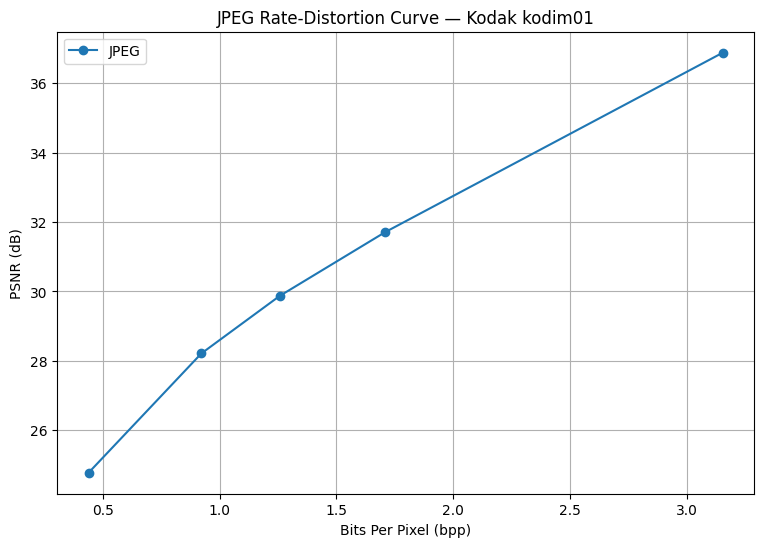

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from PIL import Image

qualities = [10, 30, 50, 70, 90]
results = []

width, height = original.size

for quality in qualities:

    buffer = BytesIO()
    original.save(
        buffer,
        format="JPEG",
        quality=quality
    )

    size_bytes = len(buffer.getvalue())
    buffer.seek(0)

    reconstructed = Image.open(buffer).convert("RGB")

    metrics = evaluate_images(original, reconstructed)

    results.append({
        "Codec": "JPEG",
        "Quality": quality,
        "bpp": 8 * size_bytes / (width * height),
        "PSNR": metrics["PSNR (dB)"],
        "SSIM": metrics["SSIM"],
        "MS-SSIM": metrics["MS-SSIM"]
    })

df = pd.DataFrame(results).sort_values("bpp")
display(df)

plt.figure(figsize=(9, 6))
plt.plot(
    df["bpp"],
    df["PSNR"],
    marker="o",
    label="JPEG"
)

plt.xlabel("Bits Per Pixel (bpp)")
plt.ylabel("PSNR (dB)")
plt.title("JPEG Rate-Distortion Curve — Kodak kodim01")
plt.grid(True)
plt.legend()
plt.show()


In [6]:

from google.colab import files

uploaded = files.upload()


Saving scale_hyperprior.png to scale_hyperprior.png
Saving kodim01_AI_reconstructed.png to kodim01_AI_reconstructed.png
Saving cheng2020_anchor.png to cheng2020_anchor.png


In [7]:

from PIL import Image
from pathlib import Path
import pandas as pd

names = {
    "Factorized Prior": "kodim01_AI_reconstructed.png",
    "Scale Hyperprior": "scale_hyperprior.png",
    "Cheng2020 Anchor": "cheng2020_anchor.png"
}

ai_results = []

for model_name, filename in names.items():
    path = Path("/content") / filename

    if not path.exists():
        print("Missing:", filename)
        continue

    reconstructed = Image.open(path).convert("RGB")
    metrics = evaluate_images(original, reconstructed)

    ai_results.append({
        "Codec": model_name,
        **metrics
    })

df_ai = pd.DataFrame(ai_results)
display(df_ai)


,Codec,PSNR (dB),SSIM,MS-SSIM
0,Factorized Prior,27.021075,0.774686,0.952564
1,Scale Hyperprior,28.676001,0.836260,0.966837
2,Cheng2020 Anchor,28.860212,0.838406,0.967670


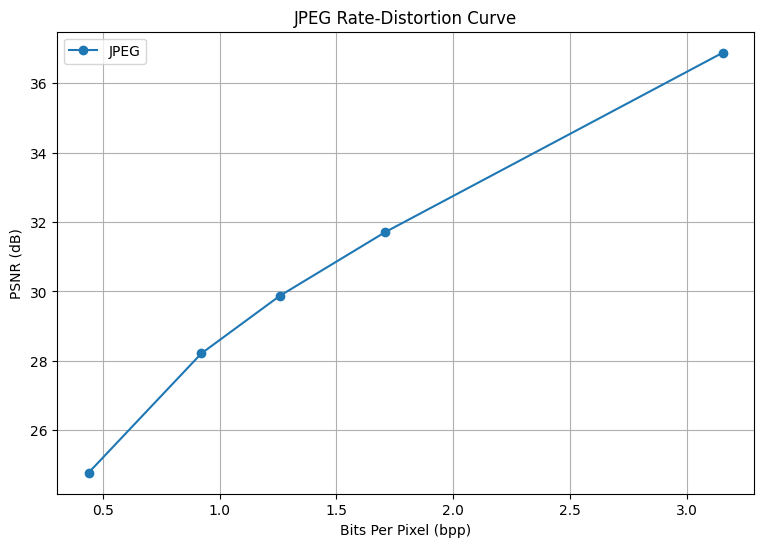

results saved!


In [8]:

from pathlib import Path

output_folder = Path(
    "/content/DIP_Project/results"
)
output_folder.mkdir(parents=True, exist_ok=True)

# Save JPEG measurements
df.to_csv(
    output_folder / "jpeg_rd_results.csv",
    index=False
)

# Save available AI quality measurements
df_ai.to_csv(
    output_folder / "ai_quality_results.csv",
    index=False
)

# Save JPEG rate-distortion graph
plt.figure(figsize=(9, 6))
plt.plot(
    df["bpp"],
    df["PSNR"],
    "o-",
    label="JPEG"
)
plt.xlabel("Bits Per Pixel (bpp)")
plt.ylabel("PSNR (dB)")
plt.title("JPEG Rate-Distortion Curve")
plt.grid(True)
plt.legend()
plt.savefig(
    output_folder / "jpeg_rd_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("results saved!")
